## Introduction

Hello, and welcome to my midterm project! The NFL, in partnership with Kaggle, has just recently posted their annual Big Data Bowl, where thousands of students across the world create projects from massive open source NFL data sets. I plan to participate for the first time this year, so this project is like a warmup! Unfortunately, the datasets are far too large to use in Jupyter Lab, so I'll be using a similar dataset. Using the [NFLFastR Library](https://nflfastr.com/), I was able to locally download a massive CSV that contains all the play-by-play data from the first 6 weeks of the 2026-27 NFL season. In this project, I will be creating several visualizations and models that leverage the advanced statistics made available in this dataset. Our overarching goal is: *How can we better understand the events, decisions, and nuances of a football game by analyzing play-by-play data?* Let's start by loading in our libraries and our dataset.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
import plotly.io as pio
pio.renderers.default = "plotly_mimetype+notebook_connected"
import math
import altair as alt
from IPython.display import HTML
import uuid
from IPython.display import HTML

def show_altair(chart):
    div_id = f"altair-{uuid.uuid4().hex[:8]}"
    spec = chart.to_json(indent=None)
    return HTML(f"""
<div id="{div_id}"></div>
<script>
(function () {{
  // Quarto pages include require.js, which hijacks Vega's scripts unless define is hidden while they load.
  if (!window.__altairReady) {{
    window.__altairReady = new Promise(function (resolve, reject) {{
      var libs = [
        "https://cdn.jsdelivr.net/npm/vega@6",
        "https://cdn.jsdelivr.net/npm/vega-lite@6",
        "https://cdn.jsdelivr.net/npm/vega-embed@7"
      ];
      var savedDefine = window.define;
      window.define = undefined;
      (function load(i) {{
        if (i === libs.length) {{
          window.define = savedDefine;
          resolve();
          return;
        }}
        var s = document.createElement("script");
        s.src = libs[i];
        s.onload = function () {{ load(i + 1); }};
        s.onerror = function () {{ window.define = savedDefine; reject(new Error("Failed to load " + libs[i])); }};
        document.head.appendChild(s);
      }})(0);
    }});
  }}
  window.__altairReady.then(function () {{
    vegaEmbed("#{div_id}", {spec}, {{actions: false}});
  }});
}})();
</script>
""")

data = pd.read_csv("data/play_by_play_2026.csv", low_memory = False)
data.head(5)

,play_id,game_id,old_game_id,home_team,away_team,season_type,week,posteam,posteam_type,defteam,...,out_of_bounds,home_opening_kickoff,qb_epa,xyac_epa,xyac_mean_yardage,xyac_median_yardage,xyac_success,xyac_fd,xpass,pass_oe
0,1,2026_01_ARI_LAC,2026091308,LAC,ARI,REG,1,NaN,NaN,NaN,...,0,0,0.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,39,2026_01_ARI_LAC,2026091308,LAC,ARI,REG,1,ARI,away,LAC,...,0,0,0.291195,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,62,2026_01_ARI_LAC,2026091308,LAC,ARI,REG,1,ARI,away,LAC,...,0,0,1.730269,0.402115,5.429666,3.0,1.0,1.000000,0.453482,54.651752
3,87,2026_01_ARI_LAC,2026091308,LAC,ARI,REG,1,ARI,away,LAC,...,0,0,-0.288451,NaN,NaN,NaN,NaN,NaN,0.402800,-40.280038
4,109,2026_01_ARI_LAC,2026091308,LAC,ARI,REG,1,ARI,away,LAC,...,0,0,-0.889568,0.361333,4.490768,2.0,1.0,0.998909,0.616770,38.322973


## Creating an Interactive Win Probability Model with Play Outcomes

The best part of having a comprehensive play-by-play dataset is we can essentially recreate the game on a play-by-play basis. A great addition in this dataset is win probability, a measure of a team's probability to win the game at a given moment, which we can use to demonstrate the exchanges of momentum and advantages between teams throughout the game. Let's select a game from this dataset (we'll do Cardinals at Chargers in week 1, the first game listed here) and create a win probability visualization that has the following qualities:

* Interactive: a viewer can hover over every play of the game and see exactly how win probability changes based on that play
* Explanatory: the dataset gives us the exact play that corresponds to each observation, the viewer should be able to see that play
* Beautified: change variable names to make sense within the context of the game, make informed color/design choices

Let's start by creating a smaller, filtered dataset with only the columns we need.

### Filtered Dataset

In [2]:
game_1 = data[data['game_id'] == '2026_01_ARI_LAC']
game_1_select = game_1[['home_team', 'away_team', 'qtr', 'time', 'down', 'yrdln', 'ydstogo', 'desc', 'home_wp', 'away_wp', 'total_home_score', 'total_away_score']]
game_1_select[['down', 'yrdln']] = game_1_select[['down', 'yrdln']].fillna("N/A")
game_1_select['home_wp'] = round(game_1_select['home_wp'], ndigits = 4)
game_1_select['away_wp'] = round(game_1_select['away_wp'], ndigits = 4)
game_1_select

,home_team,away_team,qtr,time,down,yrdln,ydstogo,desc,home_wp,away_wp,total_home_score,total_away_score
0,LAC,ARI,1,15:00,N/A,LAC 35,0,GAME,0.5668,0.4332,0,0
1,LAC,ARI,1,15:00,N/A,LAC 35,0,11-C.Dicker kicks 60 yards from LAC 35 to ARI ...,0.5668,0.4332,0,0
2,LAC,ARI,1,14:56,1.0,ARI 30,10,(14:56) 7-J.Brissett pass deep right to 85-T.M...,0.5665,0.4335,0,0
3,LAC,ARI,1,14:18,1.0,LAC 43,10,(14:18) (Shotgun) 22-T.Allgeier right guard to...,0.5199,0.4801,0,0
4,LAC,ARI,1,13:34,2.0,LAC 41,8,(13:34) (Shotgun) 7-J.Brissett pass incomplete...,0.5174,0.4826,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...
168,LAC,ARI,4,02:00,4.0,LAC 38,7,(2:00) (Shotgun) 10-J.Herbert pass short left ...,0.0058,0.9942,14,26
169,LAC,ARI,4,01:52,1.0,LAC 44,10,(1:52) 7-J.Brissett kneels to LAC 45 for -1 ya...,0.0026,0.9974,14,26
170,LAC,ARI,4,01:11,2.0,LAC 45,11,(1:11) 7-J.Brissett kneels to LAC 46 for -1 ya...,0.0042,0.9958,14,26
171,LAC,ARI,4,00:34,3.0,LAC 46,12,(:34) 7-J.Brissett kneels to LAC 47 for -1 yards.,0.0047,0.9953,14,26


Now, let's create our visualization!

### Creating the WP Model

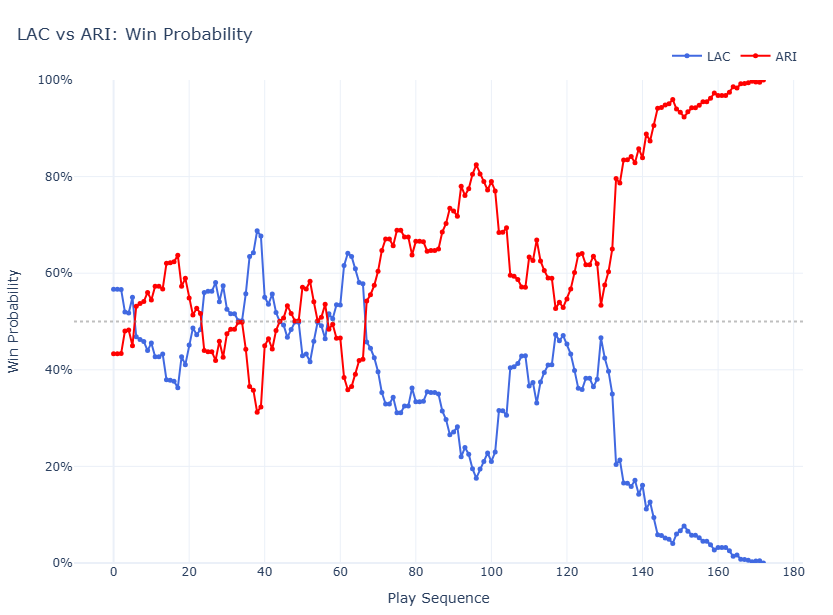

In [3]:
fig = px.line(
    game_1_select, 
    y = ['home_wp', 'away_wp'], 
    markers = True,
    width = 1100,
    height = 600,
    hover_data=['qtr', 'yrdln', 'down', 'ydstogo', 'desc', 'total_away_score', 'total_home_score'],
    labels={
        "index": "Play Sequence",
        "value": "Win Probability",
        "variable": "Team",
    },
)

fig.update_traces(
    selector=dict(name="home_wp"),
    name="LAC",
    line=dict(color="royalblue", width=2, dash = 'solid'),
    marker=dict(size=5),
    hovertemplate="<b>LAC</b>  %{y:.1%}<extra></extra>",
)

fig.update_traces(
    selector=dict(name="away_wp"),
    name="ARI",
    line=dict(color="red", width=2),
    marker=dict(size=5),
    hovertemplate=(
        "<b>ARI</b>  %{y:.1%}"
        "<br><br><b>ARI %{customdata[5]:.0f} : %{customdata[6]:.0f} LAC</b>"
        "<br><br>Q%{customdata[0]} · %{customdata[2]} & %{customdata[3]} at %{customdata[1]}"
        "<br><i>%{customdata[4]}</i>"
        "<extra></extra>"
    ),
)

fig.update_layout(
    template="plotly_white",
    hovermode="x unified",
    hoverlabel=dict(bgcolor="white", bordercolor="#ccc", font_size=12, font_family="Arial"),
    title=dict(text="LAC vs ARI: Win Probability", x=0.02),
    legend=dict(orientation="h", yanchor="bottom", y=1.02, xanchor="right", x=1, title=None),
    yaxis=dict(tickformat=".0%", range=[0, 1]),
    margin=dict(l=60, r=30, t=80, b=50),
)

fig.add_hline(y=0.5, line_dash="dot", line_color="gray", opacity=0.5)

fig.update_traces(name="LAC Win Probability", selector=dict(name="home_wp"))
fig.update_traces(name="ARI Win Probability", selector=dict(name="away_wp"))

fig.update_layout(
    hovermode="x",  
    hoverlabel=dict(bgcolor="white", font_size=11, font_color = 'black'),
)

fig.show()

### Power of the Win Probability Model

I recently just attended the Wharton Sports Business Summit, where I saw a really fascinating presentation on sports analytics that included a dynamic win probability model that predicted how likely major "choke" losses are to occur, so I was heavily inspired to make something similar. While this model is really just a visualization of a game that has already occurred (there are no predictive aspects), win probability is such a powerful way to view a game posthumously; it displays to us at exactly which junctures the tides turn within a game, as well as which plays have the largest effect on a team's chances of winning. These exact plays can be diagnosed within win probability models by computing a stat called WPA, or win probability added; this kind of calculation is common in other sports such as baseball, where we can identify plays that had the single highest effects on a team's win probability.

In general, it took a lot of work and AI optimization (I personally use Cursor, an AI platform that specializes in coding and software) to reach a visualization that I believe was legible, comprehensive, and aesthetically pleasing. Here are some issues that arose while making this visualization and how I approached them:

- Hover Card: this definitely took the longest. Originally, the interactive card would display all the values of my variables of interest, which was clunky and large. Furthermore, when I added the unified scroll, it would show each box twice! So, I remapped my variables onto a more concise card, and revamped the output into cleaner sentences, rather than just variable:value rows.
- Visualization: the model was originally extremely cramped and visually displeasing. I fixed this by adding some built in Plotly themes, enlargening the graph to reduce visual clutter, and reformatting the title/legend positions to clear up space.
- Plotly Complications: I was initially confused on how to implement two lines on one axis/graph in Plotly (it wasn't like MatPlotLib, where you can just impose multiple lines onto a graph), but educated myself on the necessary functions/parameters to adjust what I needed

We talked about win probability, but an even more exciting metric that is included in this dataset is EPA: expected points added. Based on field position, down, team, basically every predictive parameter for an offensive drive, we are able to estimate how many points we expect a team to score by the end of their current drive. Similar to WPA, we can identify the change in expected points on a play-to-play basis, giving us EPA - an incredibly strong way of detecting the most impactful plays in a game. Let's use a facet plot to compare EPA distributions between the two different major play types, being running the ball and passing the ball:

## Comparing EPA Across NFL Play Types

### Reformat Dataset

Let's create another smaller dataset, one that now includes all plays but only looks at EPA and playtype:

In [4]:
epa_set = data[['play_type', 'yards_gained', 'epa']]
epa_pass = epa_set[epa_set['play_type'] == 'pass']
epa_run = epa_set[epa_set['play_type'] == 'run']

print(pd.concat([epa_pass, epa_run], ignore_index = True))

      play_type  yards_gained       epa
0          pass          27.0  1.730269
1          pass           0.0 -0.889568
2          pass           5.0  0.105276
3          pass          11.0  1.180520
4          pass          18.0  1.658912
...         ...           ...       ...
11479       run           6.0 -0.979570
11480       run           4.0 -0.284493
11481       run           0.0 -1.233203
11482       run          -1.0 -0.406509
11483       run           6.0  0.001671

[11484 rows x 3 columns]


### Creating Dual Histograms

Now, let's create two side-by-side histograms to observe the distribution of EPA for our different play types. The reason I believe a histogram will be strongest for this comparison is to observe what I expected to be a large difference in spread; I predict that our EPA distribution will be far more spread out for passes than for runs, as runs are generally considered the safer but less explosive play option.

In [5]:
run_epa = epa_run['epa'].values
pass_epa = epa_pass['epa'].values
run_epa_mean = np.mean(run_epa)
run_epa_sd = np.std(run_epa)
pass_epa_mean = np.mean(pass_epa)
pass_epa_sd = np.std(pass_epa)

print(f"Mean of Run EPA: {run_epa_mean}")
print(f"SD of Run EPA: {run_epa_sd}")
print(f"Mean of Pass EPA: {pass_epa_mean}")
print(f"SD of Pass EPA: {pass_epa_sd}")

Mean of Run EPA: -0.04547523200099498
SD of Run EPA: 1.0093311668977432
Mean of Pass EPA: 0.032322037584691425
SD of Pass EPA: 1.5542666535838652


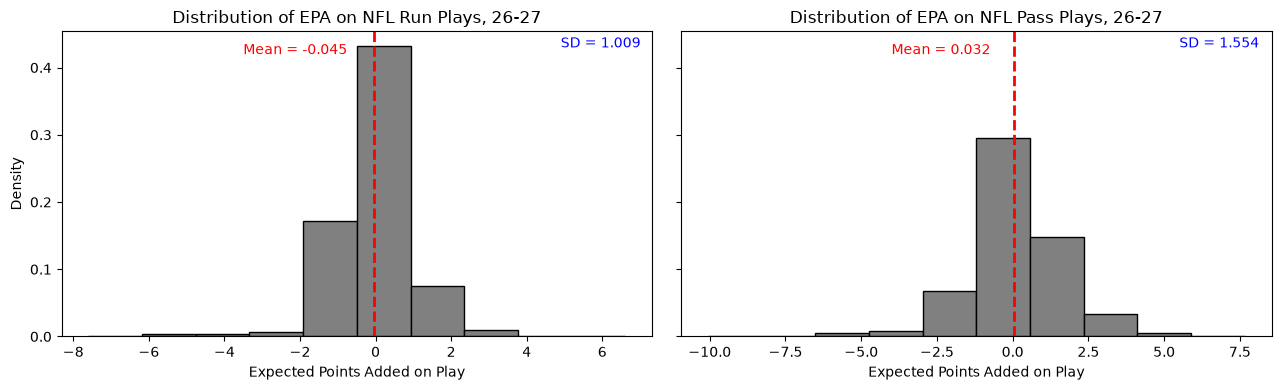

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(13,4), sharey=True)

axes[0].hist(x = run_epa, bins = 10, edgecolor = 'black', density = True, color = 'gray')
axes[0].set_title("Distribution of EPA on NFL Run Plays, 26-27")
axes[0].set_xlabel("Expected Points Added on Play")
axes[0].set_ylabel("Density")
axes[0].axvline(x = run_epa_mean, color='red', linestyle='--', linewidth=2, label=('Mean'))
axes[0].text(-3.5, 0.42, f"Mean = {round(run_epa_mean, ndigits = 3)}", color = "red")
axes[0].text(4.9, 0.43, f"SD = {round(run_epa_sd, ndigits = 3)}", color = "blue")

axes[1].hist(x = pass_epa, bins = 10, edgecolor = 'black', density = True, color = 'gray')
axes[1].set_title("Distribution of EPA on NFL Pass Plays, 26-27")
axes[1].set_xlabel("Expected Points Added on Play")
axes[1].axvline(x = pass_epa_mean, color='red', linestyle='--', linewidth=2, label=('Mean'))
axes[1].text(-4, 0.42, f"Mean = {round(pass_epa_mean, ndigits = 3)}", color = "red")
axes[1].text(5.5, 0.43, f"SD = {round(pass_epa_sd, ndigits = 3)}", color = "blue")

plt.style.use('ggplot')
plt.tight_layout()
plt.show()

### Analysis of EPA

While it's certainly possible that this could just be a down year in terms of offensive output (this is only third of a season's worth of data), we observe something very interesting: the negative mean EPA on rushing plays. It's certain that NFL teams have access to these kinds of data, so why do they continue to rush the ball despite each play, on average, decreasing their expectation to add points? 

Without looking at the data, it's commonly understood in football that running the ball is the safest play a team can run. Logically speaking, the ball is most protected when in the hands of a ballcarrier, especially one that  is typically one of the strongest on the team; when putting the ball through the air, offenses allow far more sources of risk to ball security to affect the play. Analytically speaking, there is a gargatuan disparity between interceptions (turnovers on passing plays) and fumbles (the only type of turnover that can occur on a running play, but can also occur on passing plays as well); in the last season of the NFL, there were over 3 times as many interceptions committed league-wide as fumbles (910:271 to be exact). So, why is this important to consider when questioning why teams would run a play that, on average, decreases their chance of scoring on a drive?:

1. Lack of context: it's important to note that EPA is not an **adjusted metric**, or one that takes into account game context or nuance. It only calculates the expectation of points added based on game situation, without considering game conditions or the strength of the opponent; therefore, it's highly unlikely that a league-wide mean rush EPA holds much value to individual teams.
2. Variability: it's very well known to those who watch football closely that sometimes, not losing your team the game is far more valuable than winning it. In other words, costly mistakes bear much more impact on the game than unlikely successes. While passing the football is the most direct way towards explosive plays that have huge bearings on the result of a match, these events are far more subject to disastrous outcomes that have highly pronounced EPA's; this is evidenced by the gap in EPA standard deviation between rushing and passing plays. The data demonstates what football analysts usually describe as an inherent increased risk when passing the football.
3. Game context: It's important to note that rushing the ball and staying in-bounds allows the clock to continue running, whereas passing the football runs the risk of an incompletion, which stops the clock. In all game scenarios where it might be advantageous for a team to run out the clock, teams highly favor the safer option in rushing the football that guarantees them a running timer; these plays likely have little to no impact on EPA and could be dragging down the mean.

Awesome stuff! But we can dive even deeper. Within each type of play, we obviously have several different subtypes; for passing plays, we can generally classify the type of pass into short (0-10yds), medium (10-20yds), and long(20+yds). It seems logical that the deepest passes should produce the most explosive results, but are they also the most prone to game-shifting errors? Let's split our passing data into three parts and compare their distributions using a violin plot:

## Analyzing Distribution Disparity of EPA Across Pass Types

### Editing Dataset

Let's start by reformatting our dataset. 

In [7]:
data2 = data[data['play_type'] == 'pass']
epa_pass_new = data2[['play_type', 'pass_length', 'pass_location', 'air_yards', 'epa']]

pass_type = [
    (epa_pass_new['air_yards'] < 10),
    (epa_pass_new['air_yards'] >= 10) & (epa_pass_new['air_yards'] <20),
    (epa_pass_new['air_yards'] >= 20)
]

pass_type_values = ['Short', 'Medium', 'Long']

epa_pass_new['pass_type'] = np.select(pass_type, pass_type_values, default = 'NA')
epa_pass_new = epa_pass_new.dropna()
epa_pass_new

,play_type,pass_length,pass_location,air_yards,epa,pass_type
2,pass,deep,right,22.0,1.730269,Long
4,pass,short,middle,11.0,-0.889568,Medium
6,pass,short,right,1.0,0.105276,Short
10,pass,short,left,2.0,1.180520,Short
17,pass,deep,middle,18.0,1.658912,Medium
...,...,...,...,...,...,...
16364,pass,deep,right,16.0,-3.000016,Medium
16367,pass,short,right,-5.0,-0.371444,Short
16372,pass,short,middle,4.0,0.432801,Short
16374,pass,deep,middle,17.0,0.723483,Medium


Let's add another layer of distinction to our data. Another important category to differentiate across several datapoints is the location of the pass, not just the length; it's generally considered riskier to throw over the middle of the field, where more defenders have a chance of making a play on the ball. Let's create another categorical variable in our modified dataset that determines whether a pass was thrown inside or outside the hashmarks (over the middle of the field or towards the outside):

In [8]:
location_type = [
    (epa_pass_new['pass_location'].isin(['left', 'right'])),
    (epa_pass_new['pass_location'] == 'middle')
]

location_type_values = ['Outside Hashes', 'Inside Hashes']

epa_pass_new['location'] = np.select(location_type, location_type_values, default = 'NA')
epa_pass_new

,play_type,pass_length,pass_location,air_yards,epa,pass_type,location
2,pass,deep,right,22.0,1.730269,Long,Outside Hashes
4,pass,short,middle,11.0,-0.889568,Medium,Inside Hashes
6,pass,short,right,1.0,0.105276,Short,Outside Hashes
10,pass,short,left,2.0,1.180520,Short,Outside Hashes
17,pass,deep,middle,18.0,1.658912,Medium,Inside Hashes
...,...,...,...,...,...,...,...
16364,pass,deep,right,16.0,-3.000016,Medium,Outside Hashes
16367,pass,short,right,-5.0,-0.371444,Short,Outside Hashes
16372,pass,short,middle,4.0,0.432801,Short,Inside Hashes
16374,pass,deep,middle,17.0,0.723483,Medium,Inside Hashes


### Visualizing Distributions

Now that we have reformatted our data using a custom rule for short/medium/long passes (original data set had only short and long, so I made an edit), let's visualize the distributions of expected points added across different pass lengths and juxtapose their centering and spread. The reason I decided to use a violin chart as opposed to a standard boxplot is because it demonstrates the density of a distribution at certain intervals, which should be helpful for us to interpret the **spread** of our distributions. We'll also split these plots in two subplots each, based on their location, to observe any disparity there:

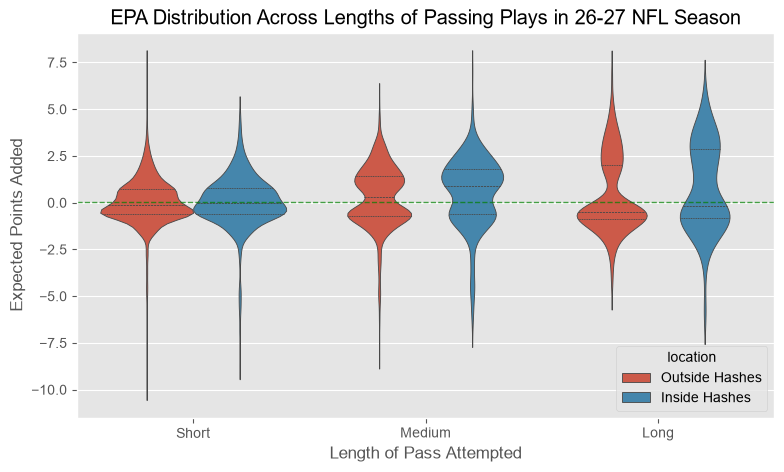

In [9]:
plt.figure(figsize = (9,5))

sns.violinplot(
    data = epa_pass_new, 
    x = 'pass_type', 
    y = 'epa', 
    order = ['Short', 'Medium', 'Long'],
    inner = 'quart',
    split = False,
    hue = 'location'
)

plt.axhline(y = pass_epa_mean, linestyle = '--', linewidth = 1, color = 'green', alpha = 0.7)
plt.title("EPA Distribution Across Lengths of Passing Plays in 26-27 NFL Season")
plt.xlabel("Length of Pass Attempted")
plt.ylabel("Expected Points Added")

plt.style.use('seaborn-v0_8-whitegrid')
plt.show()

### Juxtaposing Distributions Across Several Layers

There's a lot to unpack here, so let's work through these comparisons one layer at a time.

#### How does the distribution of EPA vary across pass lengths?

Initially speaking, it appears that our distribution of EPA across pass lengths substantiates my initial suspection that passes with higher length/depth are more volatile as it pertains to their result. Short passes have the most restricted distribution of EPA, as they are simultaneously the safest and least explosive type of pass to attempt; these plays are generally easy to execute, include all kinds of heavily designed quick-hitters (like screen passes), and are unlikely to have game-altering outcomes.

However, as we shift to medium and long passes, our distributions become far more spread out, with tails reaching extremely positive and negative values. This aligns with traditional offensive logic in the NFL, which expects a higher variability of play outcome the further the ball is pushed down the field. However, there is an interesting disparity in distribution shape between medium and deep passes. Medium passes appear to be bimodal centered around -1 and 1 EPA, while deep passes share a somewhat similar shape but are heavily favored more towards the -1 EPA side. This tells us that the success rate of deep passes is likely lower than that of medium passes, and that these passes are more subject to meaningful error; however, no pass type reaches higher levels of expected points added other than deep passes, making their upside highly desirable. 

I love viewing these charts side-by-side, as I believe it effectively summarizes the equilibrium that coaches are constantly trying to maintain between generating yards/scores while taking care of the football.

#### How does the distribution of EPA vary across pass location?

Unfortunately, we don't observe a noticeable trend when comparing passes thrown towards the boundaries as opposed to across the middle. However, the within hash distributions seem to generally be more spread out than the outside hash distribution, suggesting an extra degree of volatility when passing over the middle (especially as our pass length increases); this aligns with my expectation of a higher risk when comparing these categories.

This is a great example of how visualizing distributions across levels of a variable help us contexualize traditional coaching logic.

## Switch to Player-Sided Statistics

Thus far, we've looked as overarching data that spans the entire league; this is helpful when considering league-wide trends, but much of the extremity and nuance that comes from viewing individual teams and players is suppressed and averaged out. Let's now use a dataset from NFL's own NextGenStats, an online platform that provides some more specialized and specific metrics for players. Let's read in 3 new CSVs for passing, rushing, and receiving:

In [10]:
passing = pd.read_csv("data/ngs_passing_2026_reg.csv")
rushing = pd.read_csv("data/ngs_rushing_2026_reg.csv")
receiving = pd.read_csv("data/ngs_receiving_2026_reg.csv")

for df in ([passing, rushing, receiving]):
    print(df.columns)

Index(['player', 'team', 'position', 'games_played', 'avg_time_to_throw',
       'avg_completed_air_yards', 'avg_intended_air_yards',
       'avg_air_yards_differential', 'aggressiveness_pct',
       'max_completed_air_distance', 'avg_air_yards_to_sticks', 'attempts',
       'completions', 'pass_yards', 'pass_touchdowns', 'interceptions',
       'passer_rating', 'completion_pct', 'expected_completion_pct',
       'completion_pct_above_expected', 'avg_air_distance',
       'max_air_distance'],
      dtype='str')
Index(['player', 'team', 'position', 'efficiency',
       'pct_attempts_vs_8plus_defenders', 'avg_time_to_los', 'rush_attempts',
       'rush_yards', 'expected_rush_yards', 'rush_yards_over_expected',
       'avg_rush_yards', 'rush_yards_over_expected_per_att',
       'rush_pct_over_expected', 'rush_touchdowns'],
      dtype='str')
Index(['player', 'team', 'position', 'avg_cushion', 'avg_separation',
       'avg_intended_air_yards', 'pct_share_of_intended_air_yards',
       'rec

## Are Aggressive Quarterbacks More Likely to Turn the Ball Over?

A while ago, as a personal project for my TikTok page, I created a graph using NextGenStats that compared a quarterback's aggressiveness (percentage of passes thrown to a receiver with a defender within 1 yard of proximity) with their expected completion percentage (removes receiver error). My goal with this project is to draw comparisons between how accurate a quarterback is and how often they attempt to fit balls into tight windows. Now, we're going to revisit the topic, but now comparing aggressiveness and interceptions: are aggressive quarterbacks more likely to turn the ball over?

### Reformatting Dataset + Creating Visualization

In [11]:
passing_new = passing[['player', 'team', 'aggressiveness_pct', 'interceptions']]
correlation = passing_new['aggressiveness_pct'].corr(passing_new['interceptions'])
points = alt.Chart(passing_new).mark_circle(size=60, opacity=1).encode(
    x=alt.X('aggressiveness_pct:Q', title='Aggressiveness %', scale=alt.Scale(zero=False)),
    y=alt.Y('interceptions:Q', title='Interceptions'),
    color=alt.value('#013369'),
    tooltip=[
        alt.Tooltip('player:N', title='Player'),
        alt.Tooltip('team:N', title='Team'),
        alt.Tooltip('aggressiveness_pct:Q', title='Aggressiveness %', format='.1f'),
        alt.Tooltip('interceptions:Q', title='Interceptions'),
    ],
)
trend = points.transform_regression(
    'aggressiveness_pct', 'interceptions'
).mark_line(color='#97233F', strokeDash=[6, 4])
corr_anno = alt.Chart(pd.DataFrame({'t': [0]})).mark_text(
    text=f'r = {correlation:.3f}',
    x=10, y=15, align='left',
    fontSize=12, color='black',
)
output = (
    (points + trend + corr_anno)
    .properties(title='NFL QB Aggressiveness vs Interceptions', width=500, height=500)
    .configure_title(fontSize=20, font='Arial', anchor='start', color='black')
    .configure_view(strokeWidth=2, stroke='black', fill='lightgray')
    .interactive()
)

show_altair(output)

### Why don't we observe a clear correlation between aggressive quarterbacks and interceptions thrown?

Before creating the interactive scatter plot between QB aggressiveness and interceptions, I calculated the correlation and regression line between the two variables to get an idea of how often high interception totals correspond with high aggression percentages; what we observe, both numerically and graphically, is a very weak, positive relationship between aggression and turnovers. It seems logically that quarterbacks who attempt more passes with defenders in close range would throw more interceptions, so why don't we observe a stronger correlation? Here's what I think:

1. Aggressiveness would really benefit from adjustment. The metric only tells us the percentage of passes with a defender in very close proximity, but it doesn't tell us the average separation score (yards of distance between receiver and defensive player) of that quarterback's receivers. This would be a valuable adjustment that contextualizes a quarterback's decisionmaking without labeling them as inherently aggressive or passive; a great example of this necessity would be Caleb Williams, a highly daring quarterback who has a relatively low aggressiveness percentage due to a well-schemed offense by playcalling mastermind Ben Johnson that gets receivers open more often.
2. Player variability is something to consider. Interceptions usually fall along a spectrum that viewers can perceive as "was it the quarterback's fault", so for a small sample size (7 weeks of an 18 week season) the number of turnovers isn't exactly indicative of quarterback quality. Furthermore, there are various other inputs to consider when diagnosing the responsibility of an interception, such as disguise coverage, outlier defensive plays, miscommunications in route running, and so much more; in retrospect, it seems highly unlikely that we could predict how many interceptions a quarterback will throw just based on their percentage of aggressive throws.

Finding connections that have actual predictive application is difficult in sports, so I hope to explore more of these correlative pairs in the future.

## Representing Team Yardage Splits Using a Stacked Bar Chart

NFL offenses can be highly diverse in how they generate their yardage, usually when considering the strength of their running game and their passing game. By viewing team's top playmakers, I want to discover how their yardage totals are split between rushing and passing, and how exactly efficient those plays are.

Since these aren't inclusive team statistics, we'll use play averages (yards per rush and yards per catch) and aggregate means based on teams, so we generate what is essentially an average yard per rush and pass for each team. Let's set up this table first:

### Creating the Averages Table

In [12]:
rush = rushing[['team', 'avg_rush_yards']]
rush['yards_per_rush'] = rush['avg_rush_yards']
rush_agg = rush.groupby('team')['yards_per_rush'].agg('mean')
rush_avg = pd.DataFrame(rush_agg)


pas = receiving[['team', 'receptions', 'yards']]
pas['yards_per_catch'] = round((pas['yards'] / pas['receptions']), ndigits = 3)
pass_agg = pas.groupby('team')['yards_per_catch'].agg('mean')
pass_avg = pd.DataFrame(pass_agg)

yardage = rush_avg.join(pass_avg)
yardage['yards_per_rush'] = round(yardage['yards_per_rush'], ndigits = 2)
yardage['yards_per_catch'] = round(yardage['yards_per_catch'], ndigits = 2)
yardage.head(5)

,yards_per_rush,yards_per_catch
team,,
ATL,4.68,15.31
AZ,3.27,9.16
BAL,3.94,12.61
BUF,5.36,14.04
CAR,4.78,12.49


Now that we have created a simple table that gives us each team's average yards per rush and yards per catch, let's create a stacked bar chart that helps us understand exactly where different teams generate their yardage.

### Representing Yardage Totals with a Stacked Bar Chart

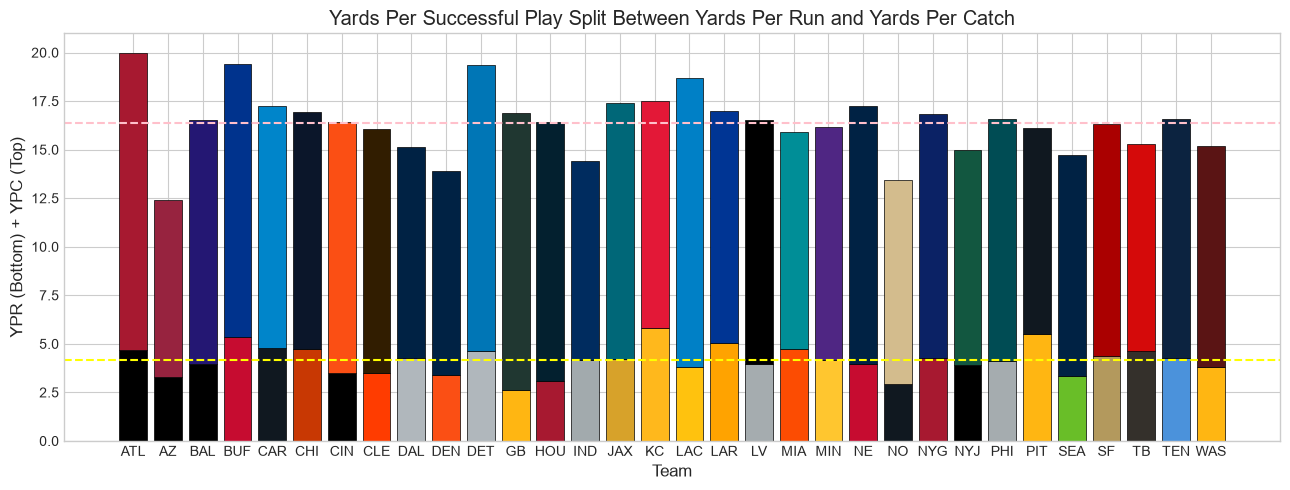

In [13]:
fig, ax = plt.subplots(figsize = (13, 5))

ax.bar(yardage.index, 
       yardage['yards_per_rush'], 
       label = 'YPR', 
       color = ["#000000", "#000000", "#000000", "#C60C30", "#101820", "#C83803", "#000000", "#FF3C00",
                    "#B0B7BC", "#FB4F14", "#B0B7BC", "#FFB612", "#A71930", "#A2AAAD", "#D7A22A", "#FFB81C",
                    "#FFC20E", "#FFA300", "#A5ACAF", "#FC4C02", "#FFC62F", "#C60C30", "#101820", "#A71930",
                    "#000000", "#A5ACAF", "#FFB612", "#69BE28", "#B3995D", "#34302B", "#4B92DB", "#FFB612"],
       edgecolor = 'black'
)

ax.bar(yardage.index, 
       yardage['yards_per_catch'], 
       bottom = yardage['yards_per_rush'], 
       label = 'YPC', 
       color = ["#A71930", "#97233F", "#241773", "#00338D", "#0085CA", "#0B162A", "#FB4F14", "#311D00",
                  "#002244", "#002244", "#0076B6", "#203731", "#03202F", "#002C5F", "#006778", "#E31837",
                  "#0080C6", "#003594", "#000000", "#008E97", "#4F2683", "#002244", "#D3BC8D", "#0B2265",
                  "#125740", "#004C54", "#101820", "#002244", "#AA0000", "#D50A0A", "#0C2340", "#5A1414"],
       edgecolor = 'black'
)

ax.set_title("Yards Per Successful Play Split Between Yards Per Run and Yards Per Catch")
ax.set_xlabel("Team")
ax.set_ylabel("YPR (Bottom) + YPC (Top)")
ax.axhline(y = yardage['yards_per_rush'].mean(), color = 'yellow', linestyle = '--')
ax.axhline(y = (yardage['yards_per_rush'].mean() + yardage['yards_per_catch'].mean()), color = 'pink', linestyle = '--')

plt.tight_layout()
plt.style.use('seaborn-v0_8-whitegrid')
plt.show()

### Fallbacks of this Design

While this is an interesting way of comparing yards per run and yards per catch, there are several flaws in this chart that prevent us from being able to draw effective conclusions. Here are the issues that came out and how I propose fixing them:

* Inequity between rushing and passing averages: I didn't consider the inherent disparity between considering average rushing yards and average passing yards. Not only are rushing yards per attempt going to be far lower than yards per catch naturally, but it also doesn't take into account that run plays are almost 100% successful, whereas yards per catch already assumes that the pass is completed and ignores the chance of that completion. To fix this, I plan on changing yards per reception to yards per target (closest thing to an attempt for passing), so we get a more generalized "efficiency" rating".
* Visuals: I had Cursor generate me two lists of each team's primary and secondary color hexcodes, so that each bar could visually represent each team; however, I feel like this just creates confusion about the split between YPR and YPC. Furthermore, there are so many teams that the graph is too large to fit in one panel (the size of the graph is the smallest it can be without the text labels overlapping). To fix this, I plan on either reformatting the graph vertically, or splitting it into two panels.

Now, let's redesign to make it more dynamic, legibile, and fitting to our research interest.


## Recreating The Stacked Chart

We'll change yards per catch into yards per target, then create our new chart with some visual overhaul:

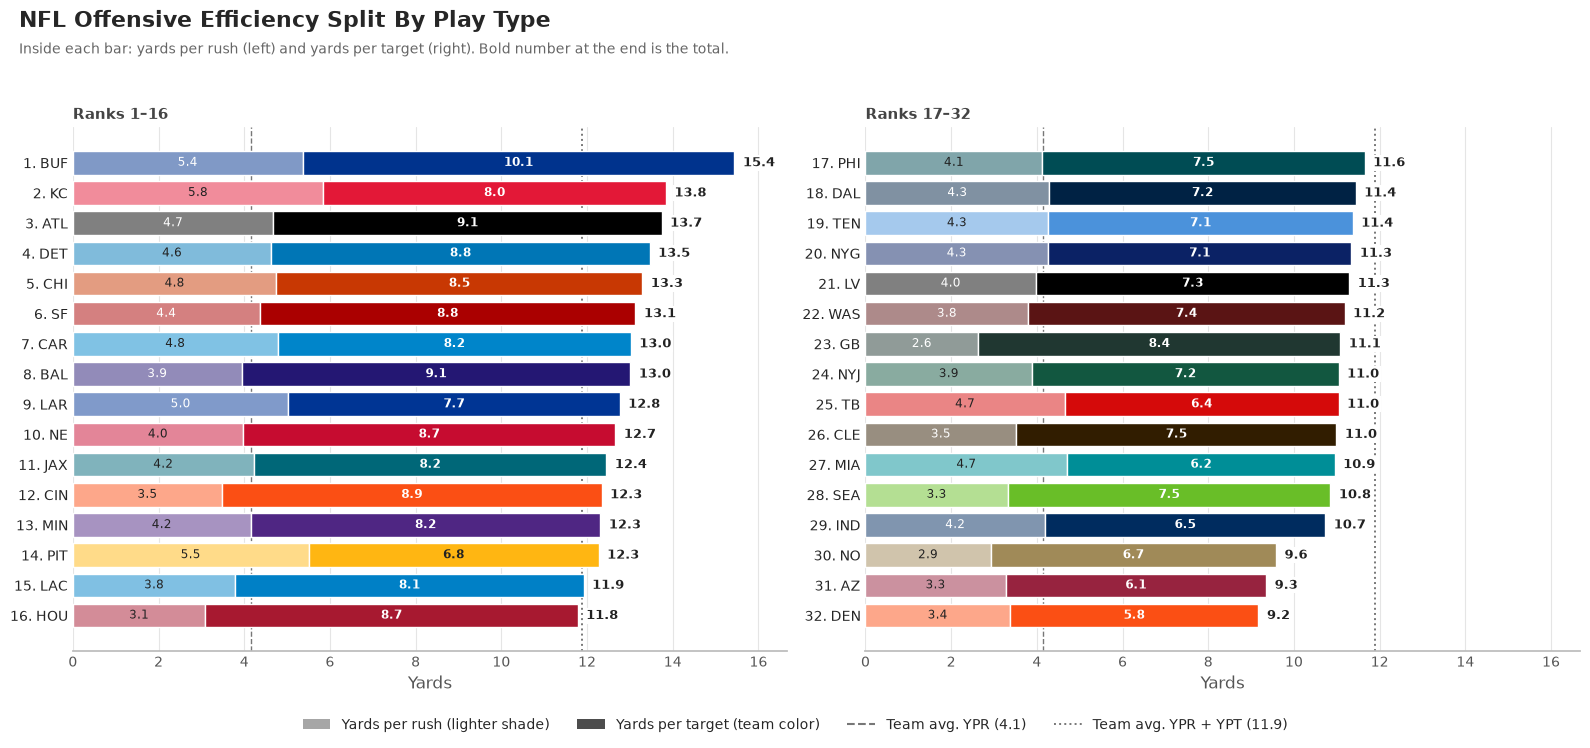

In [14]:
pas2 = receiving[['team', 'targets', 'yards']]
pas2['yards_per_target'] = round((pas2['yards'] / pas2['targets']), ndigits = 3)
pass_agg2 = pas2.groupby('team')['yards_per_target'].agg('mean')
pass_avg2 = pd.DataFrame(pass_agg2)

yardage2 = rush_avg.join(pass_avg2)
yardage2['yards_per_rush'] = round(yardage2['yards_per_rush'], ndigits = 2)
yardage2['yards_per_target'] = round(yardage2['yards_per_target'], ndigits = 2)

from matplotlib.colors import to_rgb
from matplotlib.patches import Patch

team_colors = {
    "ATL": "#000000", "AZ": "#97233F", "BAL": "#241773", "BUF": "#00338D",
    "CAR": "#0085CA", "CHI": "#C83803", "CIN": "#FB4F14", "CLE": "#311D00",
    "DAL": "#002244", "DEN": "#FB4F14", "DET": "#0076B6", "GB": "#203731",
    "HOU": "#A71930", "IND": "#002C5F", "JAX": "#006778", "KC": "#E31837",
    "LAC": "#0080C6", "LAR": "#003594", "LV": "#000000", "MIA": "#008E97",
    "MIN": "#4F2683", "NE": "#C60C30", "NO": "#A08A58", "NYG": "#0B2265",
    "NYJ": "#125740", "PHI": "#004C54", "PIT": "#FFB612", "SEA": "#69BE28",
    "SF": "#AA0000", "TB": "#D50A0A", "TEN": "#4B92DB", "WAS": "#5A1414",
}

def rush_shade(color, amount=0.5):
    """Mix a team color with white; amount=0 is the original color, 1 is white."""
    return tuple(ch + (1 - ch) * amount for ch in to_rgb(color))

def text_color(color):
    r, g, b = to_rgb(color)
    return "#222222" if 0.299 * r + 0.587 * g + 0.114 * b > 0.6 else "white"

plt.style.use("seaborn-v0_8-white")
plt.rcParams.update({"font.family": "DejaVu Sans", "axes.titleweight": "bold"})

data = yardage2.copy()
data["total"] = data["yards_per_rush"] + data["yards_per_target"]
data = data.sort_values("total", ascending=False)
data["rank"] = range(1, len(data) + 1)
avg_rush = data["yards_per_rush"].mean()
avg_total = data["total"].mean()

fig, axes = plt.subplots(1, 2, figsize=(16, 7.5), sharex=True)

for ax, chunk, panel_title in zip(axes, [data.iloc[:16], data.iloc[16:]], ["Ranks 1–16", "Ranks 17–32"]):
    labels = [f"{rank}. {team}" for team, rank in zip(chunk.index, chunk["rank"])]
    primary = [team_colors[t] for t in chunk.index]
    light = [rush_shade(team_colors[t]) for t in chunk.index]

    ax.barh(labels, chunk["yards_per_rush"], color=light, edgecolor="white", linewidth=1, height=0.78)
    ax.barh(labels, chunk["yards_per_target"], left=chunk["yards_per_rush"],
            color=primary, edgecolor="white", linewidth=1, height=0.78)

    for y, (team, row) in enumerate(chunk.iterrows()):
        ypr, ypt = row["yards_per_rush"], row["yards_per_target"]
        ax.text(ypr / 2, y, f"{ypr:.1f}", ha="center", va="center", fontsize=8.5,
                color=text_color(rush_shade(team_colors[team])))
        ax.text(ypr + ypt / 2, y, f"{ypt:.1f}", ha="center", va="center", fontsize=8.5,
                color=text_color(team_colors[team]), fontweight="bold")
        ax.text(row["total"] + 0.2, y, f"{row['total']:.1f}", va="center", fontsize=9.5,
                fontweight="bold", color="#222222", bbox=dict(facecolor="white", edgecolor="none", pad=1))

    ax.axvline(avg_rush, color="#777777", linestyle="--", linewidth=1, zorder=0)
    ax.axvline(avg_total, color="#777777", linestyle=":", linewidth=1.4, zorder=0)

    ax.invert_yaxis()
    ax.set_title(panel_title, loc="left", fontsize=11, color="#444444")
    ax.tick_params(axis="y", length=0, labelsize=10)
    ax.tick_params(axis="x", colors="#555555")
    ax.grid(axis="x", color="#E5E5E5", linewidth=0.8)
    ax.set_axisbelow(True)
    for side in ["top", "right", "left"]:
        ax.spines[side].set_visible(False)
    ax.spines["bottom"].set_color("#BBBBBB")
    ax.set_xlabel("Yards", color="#555555")

axes[0].set_xlim(0, data["total"].max() * 1.08)

legend_items = [
    Patch(facecolor=rush_shade("#4D4D4D"), label="Yards per rush (lighter shade)"),
    Patch(facecolor="#4D4D4D", label="Yards per target (team color)"),
    plt.Line2D([], [], color="#777777", linestyle="--", label=f"Team avg. YPR ({avg_rush:.1f})"),
    plt.Line2D([], [], color="#777777", linestyle=":", linewidth=1.4, label=f"Team avg. YPR + YPT ({avg_total:.1f})"),
]
fig.legend(handles=legend_items, loc="lower center", ncol=4, frameon=False, fontsize=10, bbox_to_anchor=(0.5, 0))

fig.suptitle("NFL Offensive Efficiency Split By Play Type", fontsize=16, fontweight="bold", x=0.015, ha="left")
fig.text(0.015, 0.922, "Inside each bar: yards per rush (left) and yards per target (right). Bold number at the end is the total.",
         fontsize=10, color="#666666", ha="left")
fig.tight_layout(rect=(0, 0.05, 1, 0.92))
plt.show()

### Drawing Conclusions Following Rework

Now, I would say this is a lot better to view! After implementing a visual overhaul and changing our yards per catch to yards per route, we have reached what I would describe as a preliminary  metric of **theoretical offensive efficiency**. Barring offensive errors and plays that end without an involved ballcarrier, we have what is essentially an offense's yard efficiency on successful plays. Let's match some current offensive storylines to what we see in the data:

* Top 3 scoring offenses in the NFL so far are the Rams, Bills, and Lions --> 9th, 1st, and 4th respectively
* Top 2 offensive passing over expected in the NFL are the Bengals and Panthers --> 7th and 12th, both well above league average yards per target
* Lowest 3 teams in first down rushing percentage are the Raiders, Packers, and Cardinals --> all below league average yards per rush

Overall, I'm very pleased with this redesign and I believe it makes comparisons far easier to draw and diagnose.

## Reflection

I asked Professor Yin for an extension on this midterm project because I really wanted to create a comprehensive report that displays several realistic applications of data for the sport I feel most knowledgeable in and passionate for, which is American football. I really enjoy working within the intersection of data science and sports, as I feel like my deep knowledge of sports as an avid viewer helps me create research questions and guide analysis, while my growing technical knowledge is slowly materializes as a way to communicate these findings and thoughts to other people without the same background. We've been slowly honing these skills throughout the semester, and this was an amazing opportunity to synthesize these lessons into one concerted effort.

As a primary user of R, I've always felt that it's highly superior to Python when cleaning and wrangling data, so there was definitely a bit of difficulty in reformatting and organizing my datasets for this project. Not only are there several new functions that I had to educate myself on (mergers, basic wranglers, even just calculation functions like means and standard deviations), but I'm still working on translating the usual R wrangling workflow into Python terms. R and Python are actually very similar, but to me it actually makes those small distinctions in syntax and formatting so much harder to remember. It's kind of like trying to differentiate basic words between romance languages; I speak Italian and feel like I could competently understand Spanish, but it becomes difficult to distinguish words between two extremely similar languages. This is something I hope to improve with as I continue to practice in Python and likely migrate towards as my main working language (sorry R, it's just what employers want).

A primary focus of mine throughout this project was how to present visualizations in a manner that is legible, understandable, and aesthetically pleasing; this was a concern that required a continuous loop of editing, viewing, then making minor adjustments. However, there were several large scale visual overhauls that I am very proud, one of which being the win probability model. The original model that I created looked something like this:

![Original model](assets/graphimage.png)

Not only was it extraordinarly ugly, but my interactive tooltip was showing up twice! This is where I believe AI tools are the strongest, as I lack the prerequisite knowledge to create highly specialized and detailed visualizations. However, in order for these AI tools to produce a sufficient output, you must provide a very detailed and nuanced query; specifically, for this final appearance, I had to submit multiple paragraph-length requests and edits to Cursor to redesign the code and create the design for the final tooltip. What results is what I believe to be professional-grade interactive win-probability model, and I'd like to generalize this code in the future. I am highly passionate about incorporating AI tools into human workflows, and I strongly believe that AI is at its strongest when provided intellectual property that is well thought-out and detailed; in future data visualization projects, I plan to continue to enhance the story I'd like to tell by using platforms like Cursor.

Holistically, I believe this project demonstrates the several ways in which play-by-play and analytical NFL data can substantiate what NFL fans perceive as simple game observations, underlying storylines, and traditional football theory.